# Join of the dastasets

In [150]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='left', suffixes=('_hd', '_le'))
print(joined_df['subject_id'].nunique())
joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)


# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates(keep=False).reset_index(drop=True)
joined_df.dropna(subset=['valueuom'], inplace=True)
joined_df

4392


,subject_id,hadm_id,icd_code,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,charttime_micro,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4452131,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452132,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452133,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452134,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,NaN,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Correlation between the cols

In [151]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[numeric_cols].corr("pearson")

,age,valuenum,flag,dilution_value
age,1.000000,-0.000653,0.031960,0.068537
valuenum,-0.000653,1.000000,0.023081,-0.000521
flag,0.031960,0.023081,1.000000,0.005012
dilution_value,0.068537,-0.000521,0.005012,1.000000


In [152]:
# Kendall correlation
joined_df[numeric_cols].corr("kendall")

,age,valuenum,flag,dilution_value
age,1.000000,0.004472,0.029238,0.127439
valuenum,0.004472,1.000000,-0.034033,0.003004
flag,0.029238,-0.034033,1.000000,0.010406
dilution_value,0.127439,0.003004,0.010406,1.000000


In [153]:
# Spearman correlation
joined_df[numeric_cols].corr("spearman")

,age,valuenum,flag,dilution_value
age,1.000000,0.006246,0.033456,0.154408
valuenum,0.006246,1.000000,-0.041626,0.003915
flag,0.033456,-0.041626,1.000000,0.011100
dilution_value,0.154408,0.003915,0.011100,1.000000


## Lab events profile

In [154]:
# Creating the subject profile for lab events

AttributeError: module 'src.utils.data_understanding' has no attribute 'create_subject_profile'

## Patient risk profile

In [ ]:
# Build patient-level aggregates
base = joined_df[['subject_id', 'hadm_id', 'age', 'icd_code']]

org_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['org_name']
    .nunique()
    .reset_index(name='unique_organisms_count')
)

ab_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotics_count')
)

resistance_stats = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby(['subject_id', 'hadm_id'], as_index=False)
    .agg(
        resistant_organism_count=('org_name', 'nunique'),
        resistant_antibiotic_count=('ab_name', 'nunique')
    )
)

abnormal_ratio = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .mean()
    .reset_index(name='abnormal_flag_ratio')
)

abnormal_fluids = (
    joined_df[joined_df['flag'] == 1]
    .groupby(['subject_id', 'hadm_id'])
    .agg(
        abnormal_fluid_count=('fluid', 'nunique'),
        fluids_analyzed=('fluid', lambda x: ', '.join(sorted(x.unique())))
    )
    .reset_index()
)

# Assemble risk profile
risk_profile = (
    base.merge(org_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(ab_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(resistance_stats, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_fluids, on=['subject_id', 'hadm_id'], how='left')
)


risk_profile = risk_profile.drop_duplicates(['subject_id', 'hadm_id'])
risk_profile.to_csv("../../data/profiles/risk_profile.csv")

risk_profile

,subject_id,hadm_id,age,icd_code,unique_organisms_count,unique_antibiotics_count,resistant_organism_count,resistant_antibiotic_count,abnormal_flag_ratio,abnormal_fluid_count,fluids_analyzed
0,10000980,29654838,75.0,I50,0,0,NaN,NaN,0.400000,1.0,Blood
45,10000980,26913865,75.0,I21,1,1,NaN,NaN,0.411290,1.0,Blood
169,10002013,24760295,69.0,I21,0,0,NaN,NaN,0.375000,1.0,Blood
209,10002155,23822395,69.0,I21,1,1,NaN,NaN,0.382671,1.0,Blood
3533,10004457,28723315,66.0,I35,0,0,NaN,NaN,0.285714,1.0,Blood
...,...,...,...,...,...,...,...,...,...,...,...
4451322,19998596,24860241,71.0,I48,0,0,NaN,NaN,0.525424,1.0,Blood
4451440,19998597,23720781,57.0,I31,0,0,NaN,NaN,0.562500,1.0,Blood
4451552,19998598,26940500,69.0,I47,0,0,NaN,NaN,0.250000,1.0,Blood
4451592,19998599,20343031,59.0,I30,0,0,NaN,NaN,0.482143,1.0,Blood


## Treatment Response Profiles

In [ ]:
intermediate_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'I']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

resistant_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

sensitive_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'S']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

treatment_profile = (
    joined_df[
        joined_df['ab_name'].notna() & joined_df['interpretation'].notna()
    ]
    .groupby(['subject_id', 'hadm_id', 'interpretation'])
    .agg(
        organism_count=('org_name', 'nunique'),
        antibiotic_count=('ab_name', 'nunique')
    )
    .unstack(fill_value=0)
)

treatment_profile.columns = [
    f"{metric}_{label.lower()}"
    for metric, label in treatment_profile.columns
]

treatment_profile = treatment_profile.reset_index()
treatment_profile.to_csv("../../data/profiles/treatment_profile.csv")
treatment_profile


,subject_id,hadm_id,organism_count_i,organism_count_no_interpretation,organism_count_r,organism_count_s,antibiotic_count_i,antibiotic_count_no_interpretation,antibiotic_count_r,antibiotic_count_s
0,10000980,26913865,0,1,0,0,0,1,0,0
1,10002155,23822395,0,1,0,0,0,1,0,0
2,10007058,22954658,0,1,0,0,0,1,0,0
3,10013569,22891949,0,1,0,0,0,1,0,0
4,10017531,20668418,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
2411,19990821,27777812,0,1,1,1,0,1,1,6
2412,19992875,20870047,0,1,0,1,0,1,0,1
2413,19994505,22534556,0,1,0,0,0,1,0,0
2414,19997293,28847872,0,1,0,0,0,1,0,0


## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

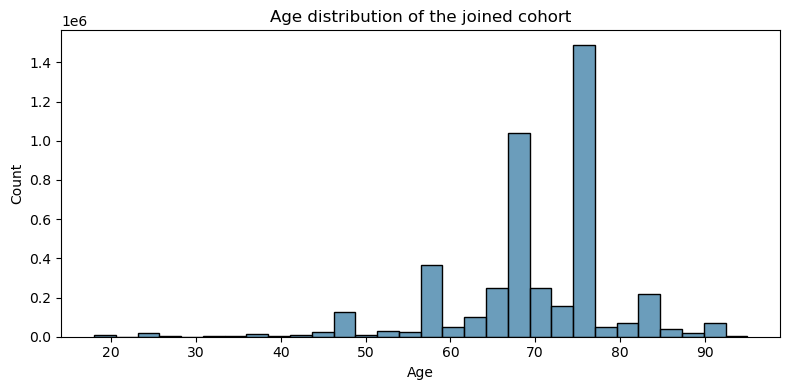

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(joined_df['age'].dropna(), bins=30, color='#3A7CA5')
plt.title('Age distribution of the joined cohort')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()